# FDA-Approved Drug-Like Compound Library
### Structure-Based Virtual Screening Dataset

**Author:** Osuna-Ramos JF  
**Repository:** [osram90/rsvf-fda-approved-library](https://github.com/osram90/rsvf-fda-approved-library)  
**License:** CC BY 4.0

A curated library of **2,611 FDA-approved compounds** ready for AutoDock Vina virtual screening.  
Filtered from 168,046 entries using Lipinski Rule of Five + Veber oral bioavailability criteria.

---

In [ ]:
# Install dependencies (run once)
# !pip install rdkit pandas matplotlib pillow

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
from rdkit import Chem
from rdkit.Chem import Draw, Descriptors
from IPython.display import display, Image as IPImage
import warnings
warnings.filterwarnings('ignore')
%matplotlib inline
print('All libraries loaded successfully.')

In [ ]:
# Load datasets
smiles_df  = pd.read_csv('data/fda_druglike_smiles.csv')
adme_df    = pd.read_csv('data/fda_with_adme.csv', low_memory=False)
funnel_df  = pd.read_csv('data/pipeline_funnel_summary.csv')
clinical_df = pd.read_csv('data/fda_clinical_drugs.csv', low_memory=False)

print(f'Drug-like SMILES: {len(smiles_df):,} compounds')
print(f'ADME descriptors: {len(adme_df):,} compounds')
print(f'Clinical set: {len(clinical_df):,} compounds')
smiles_df.head()

## Filtering Funnel

In [ ]:
# Display filtering pipeline
funnel_df['retention_%'] = funnel_df['retention_%'].round(2)
display(funnel_df[['step','count','retention_%']].style
        .bar(subset=['count'], color='#4C72B0')
        .format({'count': '{:,}', 'retention_%': '{:.2f}%'})
        .set_caption('Filtering pipeline: 168,046 → 2,611 compounds'))

In [ ]:
from IPython.display import Image as IPImage
IPImage('data/pipeline_funnel.png', width=700)

## ADME Property Distributions

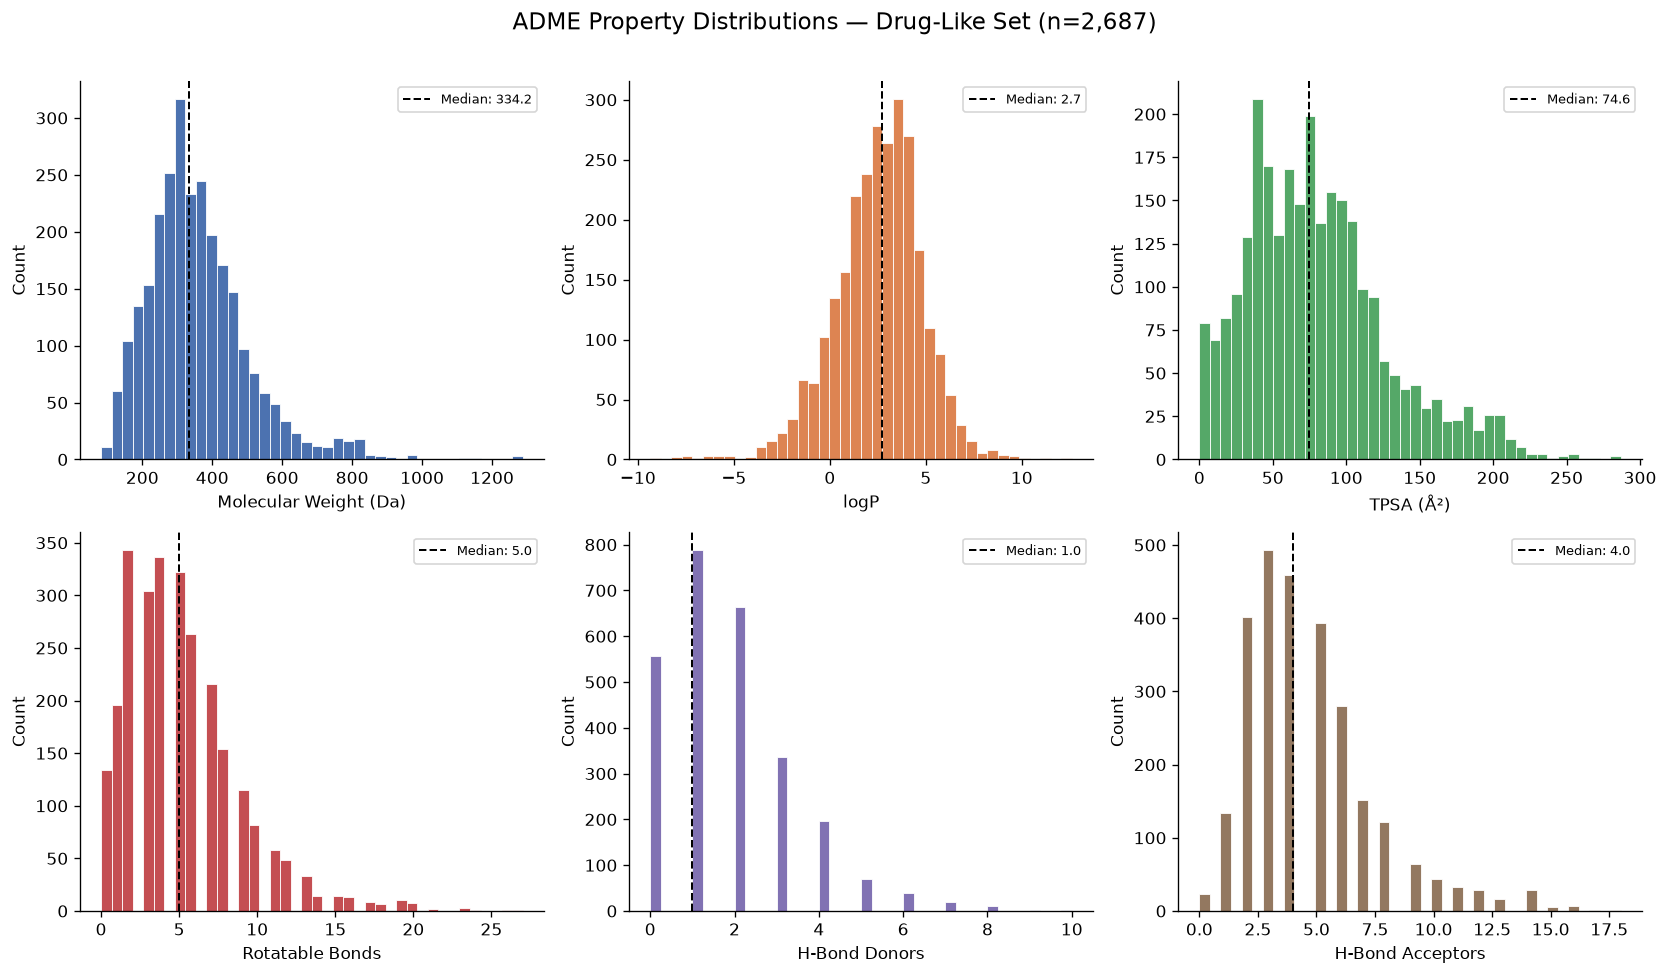

In [1]:
# Run to regenerate interactively, or view the pre-rendered output below
import pandas as pd, matplotlib.pyplot as plt
df = pd.read_csv('data/fda_with_adme.csv', low_memory=False)

props = [('MW','Molecular Weight (Da)','#4C72B0'),
         ('logP','logP','#DD8452'),
         ('TPSA','TPSA (Å²)','#55A868'),
         ('ROT','Rotatable Bonds','#C44E52'),
         ('HBD','H-Bond Donors','#8172B3'),
         ('HBA','H-Bond Acceptors','#937860')]

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
fig.suptitle('ADME Distributions — Drug-Like Set (n=2,687)', fontsize=14)
for ax, (col, label, color) in zip(axes.flat, props):
    if col in df.columns:
        vals = pd.to_numeric(df[col], errors='coerce').dropna()
        ax.hist(vals, bins=40, color=color, edgecolor='white', linewidth=0.5)
        ax.set_xlabel(label); ax.set_ylabel('Count')
        ax.axvline(vals.median(), color='black', linestyle='--', lw=1.2,
                   label=f'Median: {vals.median():.1f}')
        ax.legend(fontsize=8); ax.spines[['top','right']].set_visible(False)
plt.tight_layout(); plt.show()

## Molecule Structures (Sample)

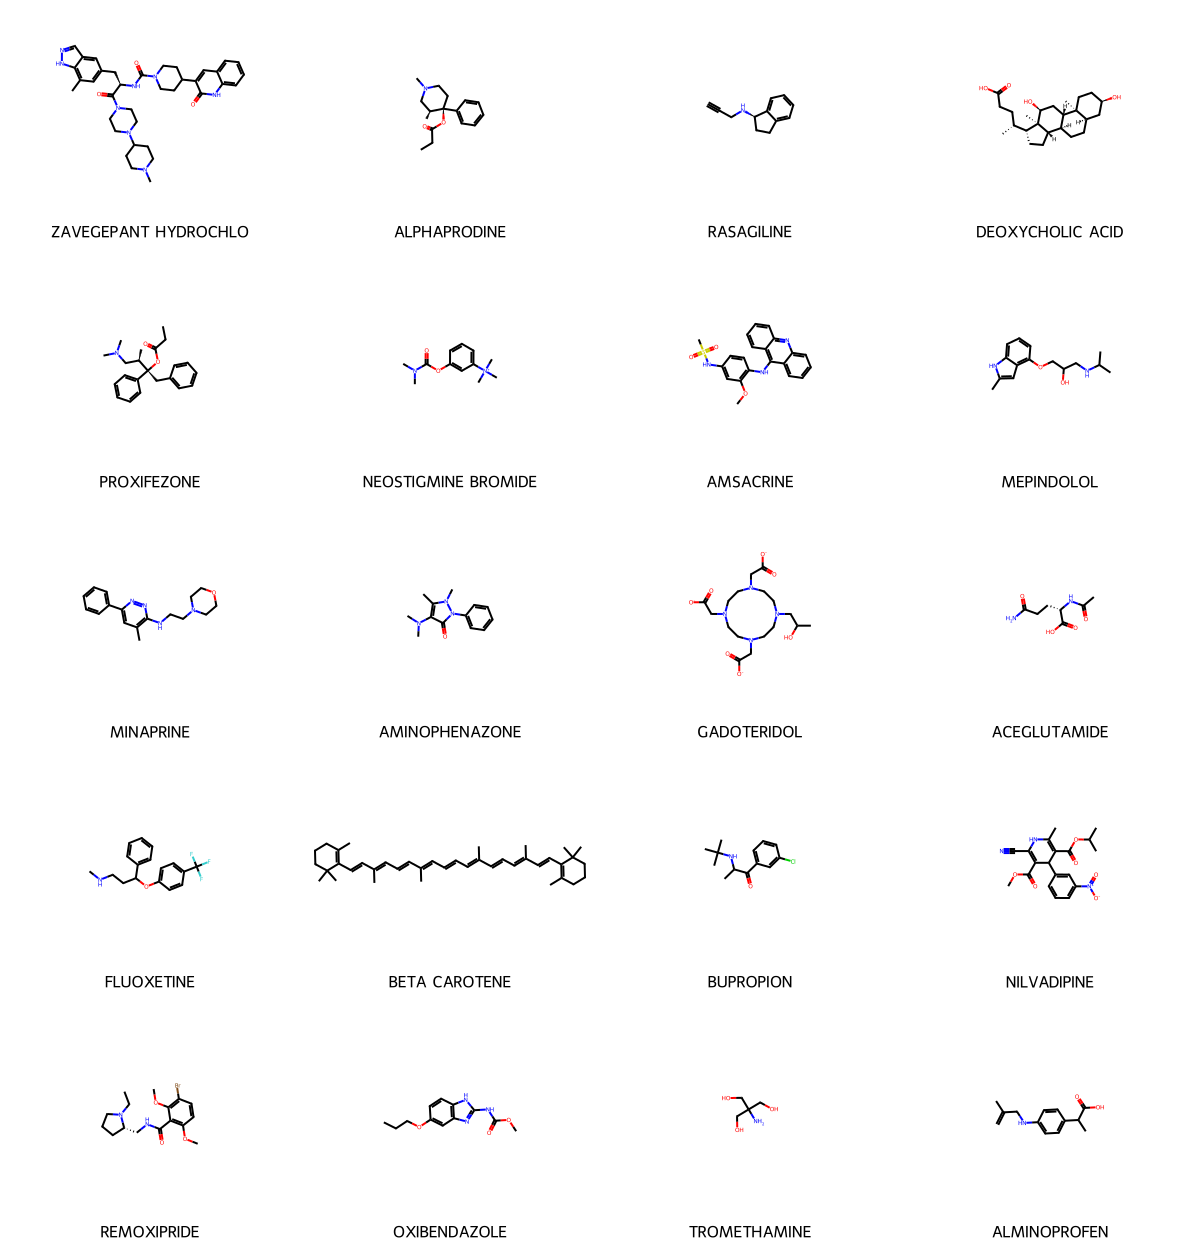

In [2]:
from rdkit import Chem
from rdkit.Chem import Draw
from IPython.display import Image as IPImage
import io

df = pd.read_csv('data/fda_druglike_smiles.csv')

# Change n to display more molecules
n = 20
sample = df[df['SMILES'].notna()].head(n)

mols, legends = [], []
for _, row in sample.iterrows():
    mol = Chem.MolFromSmiles(str(row['SMILES']))
    if mol:
        mols.append(mol)
        legends.append(str(row.get('compound_name', row['UNII']))[:22])

img = Draw.MolsToGridImage(mols, molsPerRow=4, subImgSize=(300, 250), legends=legends)
buf = io.BytesIO()
img.save(buf, format='PNG')
IPImage(buf.getvalue())

## Look Up a Specific Compound

In [ ]:
from rdkit import Chem
from rdkit.Chem import Draw
from IPython.display import Image as IPImage
import io

df = pd.read_csv('data/fda_druglike_smiles.csv')

# --- Change this to search by name or UNII ---
search_term = 'ATOVAQUONE'

results = df[df['compound_name'].str.upper().str.contains(search_term.upper(), na=False)]
print(f'Found {len(results)} match(es) for "{search_term}":')
display(results[['UNII','compound_name','SMILES','InChIKey']])

if len(results) > 0:
    mol = Chem.MolFromSmiles(results.iloc[0]['SMILES'])
    if mol:
        img = Draw.MolToImage(mol, size=(400, 300))
        buf = io.BytesIO()
        img.save(buf, format='PNG')
        IPImage(buf.getvalue())

## Filter by ADME Properties

In [ ]:
df = pd.read_csv('data/fda_with_adme.csv', low_memory=False)

# --- Adjust thresholds freely ---
filtered = df[
    (pd.to_numeric(df['MW'],   errors='coerce') <= 400) &
    (pd.to_numeric(df['logP'], errors='coerce') <= 3)   &
    (pd.to_numeric(df['TPSA'], errors='coerce') <= 90)  &
    (pd.to_numeric(df['HBD'],  errors='coerce') <= 3)
]

print(f'Compounds matching MW≤400, logP≤3, TPSA≤90, HBD≤3: {len(filtered):,}')
display(filtered.head(10))

## Export a Filtered Subset

In [ ]:
# Save the filtered subset as a new SMILES file ready for docking
smiles_df = pd.read_csv('data/fda_druglike_smiles.csv')
adme_df   = pd.read_csv('data/fda_with_adme.csv', low_memory=False)

# Merge to get ADME columns
id_col = 'UNII' if 'UNII' in adme_df.columns else adme_df.columns[0]
merged = smiles_df.merge(adme_df[[id_col,'MW','logP','TPSA','HBD','HBA']],
                          left_on='UNII', right_on=id_col, how='left')

subset = merged[
    (pd.to_numeric(merged['MW'],   errors='coerce') <= 400) &
    (pd.to_numeric(merged['logP'], errors='coerce') <= 3)
]

# Export as .smi
with open('my_custom_subset.smi', 'w') as f:
    for _, row in subset.iterrows():
        name = str(row.get('compound_name', row['UNII'])).replace(' ', '_')
        f.write(f"{row['SMILES']} {row['UNII']} {name}\n")

print(f'Exported {len(subset):,} compounds to my_custom_subset.smi')

---
## Requirements

```bash
pip install rdkit pandas matplotlib pillow
```

Or with conda:
```bash
conda install -c conda-forge rdkit pandas matplotlib pillow
```